In [1]:
from CITNP.datasets.dataset_generator import InterventionDatasetGenerator

In [2]:
generator = InterventionDatasetGenerator(
        function_generator="sinusoid",
        num_variables=2,
        sample_size=1000,
        batch_size=1,
        graph_type=["ER"],
        graph_degrees=[1],
        iterations_per_epoch=10,
)

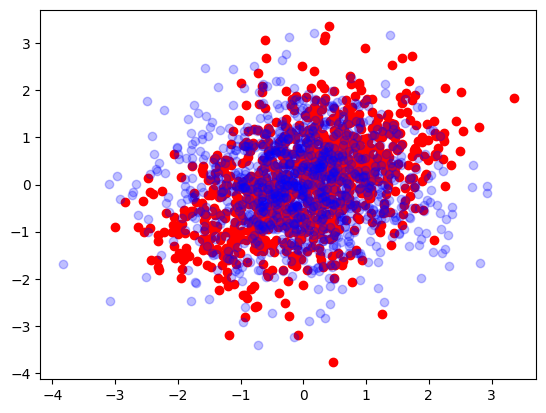

Causal graph: tensor([[0., 0.],
        [1., 0.]], dtype=torch.float64)
Intervention: tensor(0)
Outcome: 1


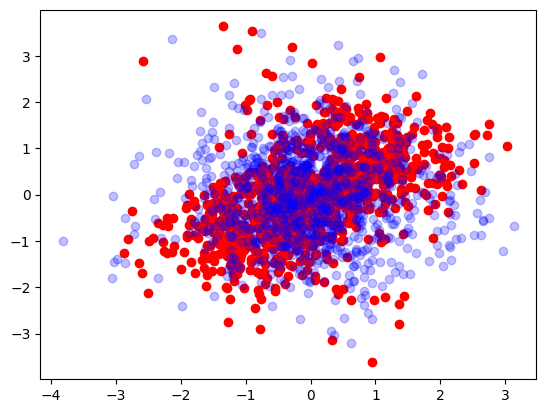

Causal graph: tensor([[0., 0.],
        [1., 0.]], dtype=torch.float64)
Intervention: tensor(0)
Outcome: 1


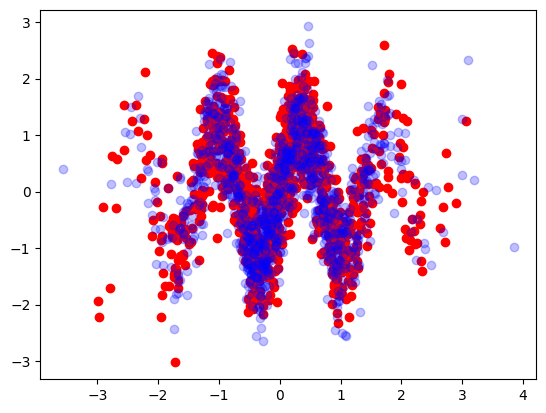

Causal graph: tensor([[0., 0.],
        [1., 0.]], dtype=torch.float64)
Intervention: tensor(1)
Outcome: 0


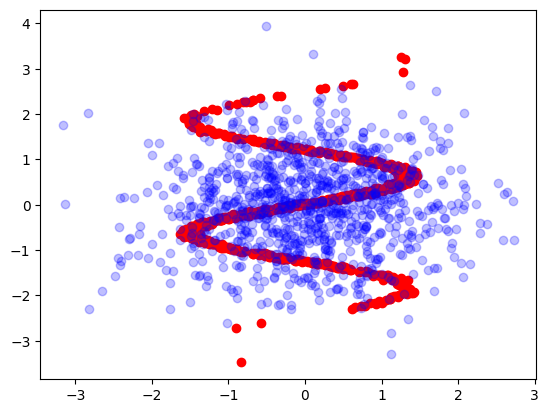

Causal graph: tensor([[0., 1.],
        [0., 0.]], dtype=torch.float64)
Intervention: tensor(1)
Outcome: 0


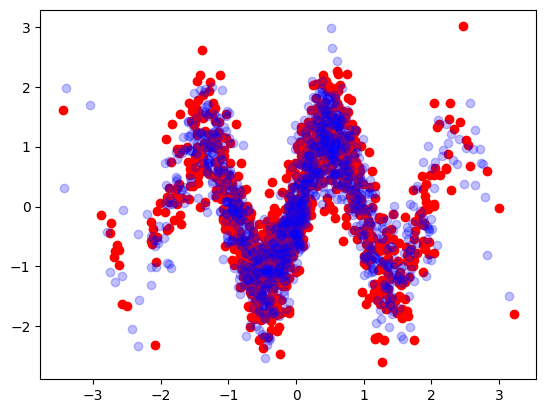

Causal graph: tensor([[0., 0.],
        [1., 0.]], dtype=torch.float64)
Intervention: tensor(1)
Outcome: 0


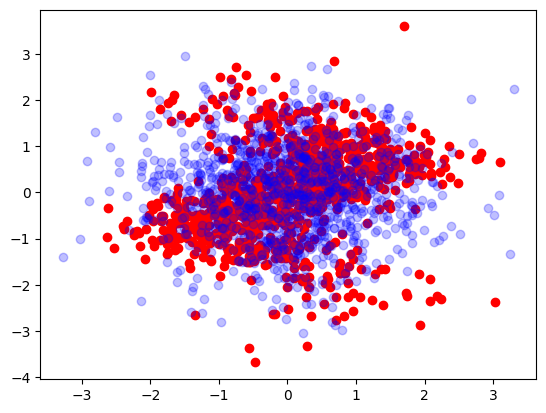

Causal graph: tensor([[0., 0.],
        [1., 0.]], dtype=torch.float64)
Intervention: tensor(0)
Outcome: 1


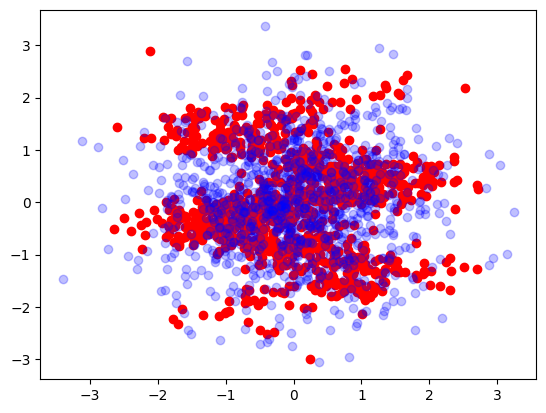

Causal graph: tensor([[0., 1.],
        [0., 0.]], dtype=torch.float64)
Intervention: tensor(1)
Outcome: 0


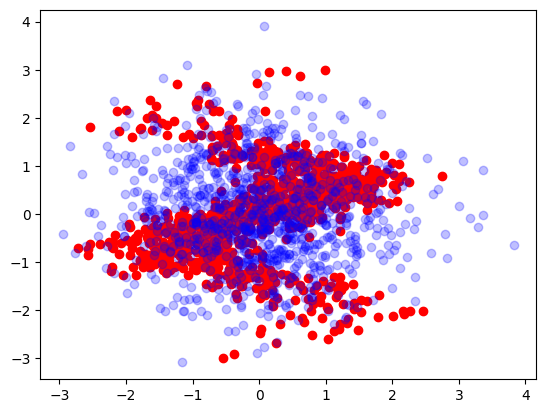

Causal graph: tensor([[0., 1.],
        [0., 0.]], dtype=torch.float64)
Intervention: tensor(1)
Outcome: 0


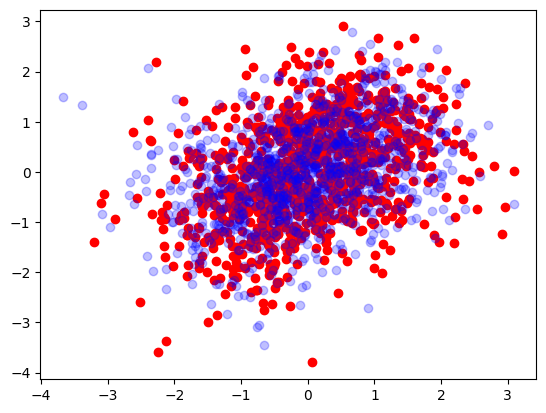

Causal graph: tensor([[0., 1.],
        [0., 0.]], dtype=torch.float64)
Intervention: tensor(0)
Outcome: 1


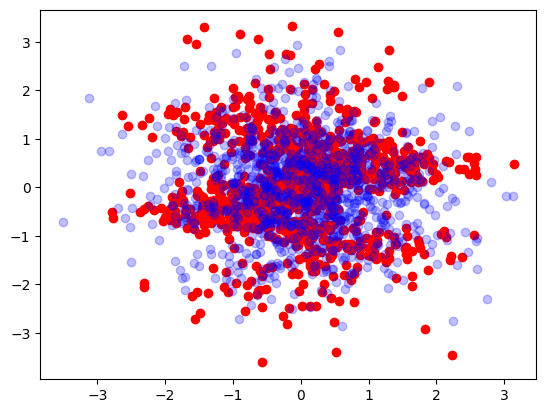

Causal graph: tensor([[0., 1.],
        [0., 0.]], dtype=torch.float64)
Intervention: tensor(1)
Outcome: 0


<Figure size 640x480 with 0 Axes>

In [4]:
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from CITNP.utils.datautils import sample_outcome_index


data_loader = DataLoader(generator, batch_size=None)


for idx, batch in enumerate(data_loader):
    (
        obs_data_array,
        int_data_array,
        causal_graphs_array,
        intvn_indices,
        variable_counts,
        masks
    ) = batch

    # Sample outcome index that is not the same as the intervention index
    outcome_index = sample_outcome_index(
        variable_counts, intvn_indices
    )

    plt.scatter(obs_data_array[0][:, intvn_indices[0]], obs_data_array[0][:, outcome_index[0]], c='r')

    plt.scatter(int_data_array[0][:, intvn_indices[0]], int_data_array[0][:, outcome_index[0]], c='b', alpha=0.25)
    plt.show()
    plt.clf()
    print("Causal graph:", causal_graphs_array[0])
    print("Intervention:", intvn_indices[0])
    print("Outcome:", outcome_index[0])

In [5]:
obs_data_array[0].mean(axis=0)

tensor([ 2.0620e-02,  5.6716e-09, -9.6428e-03], dtype=torch.float64)

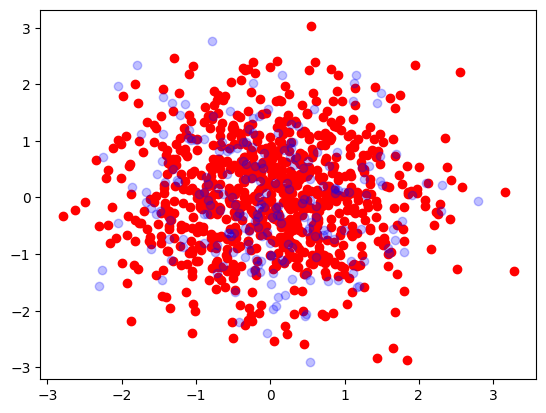

tensor(0)
tensor(1)


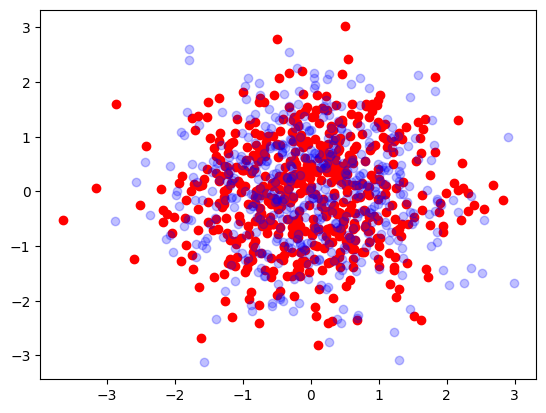

tensor(2)
tensor(0)


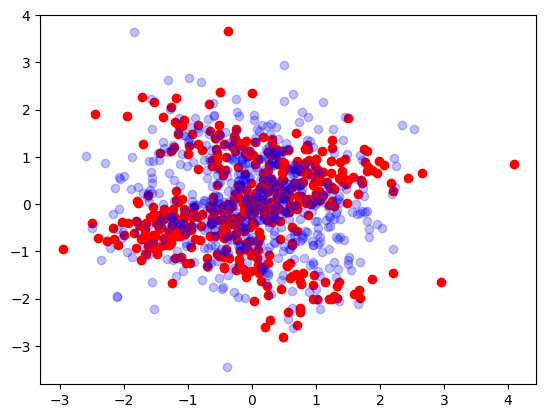

tensor(0)
tensor(1)


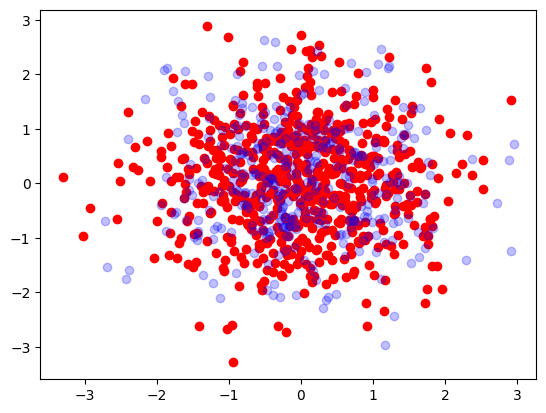

tensor(2)
tensor(0)


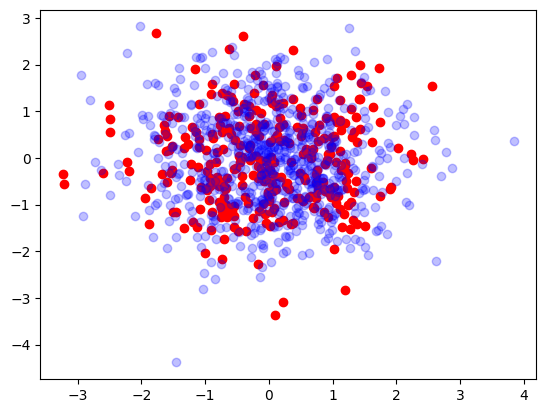

tensor(0)
tensor(2)


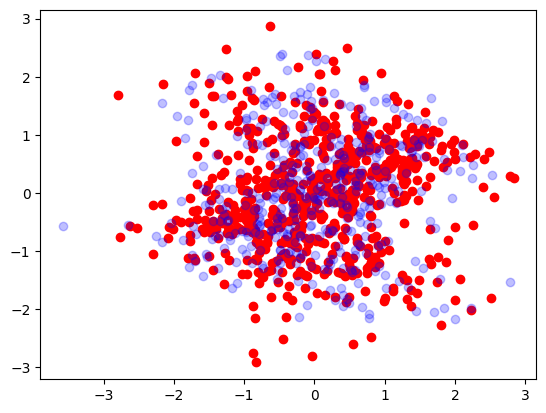

tensor(1)
tensor(0)


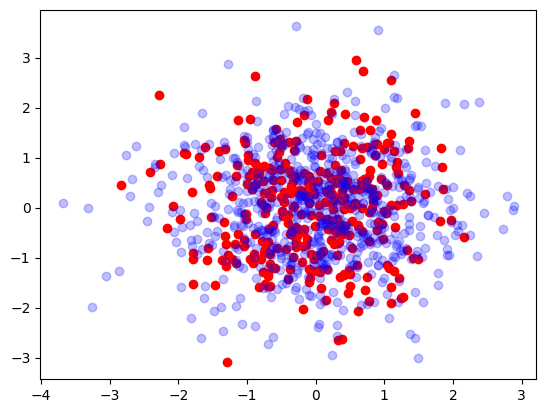

tensor(2)
tensor(1)


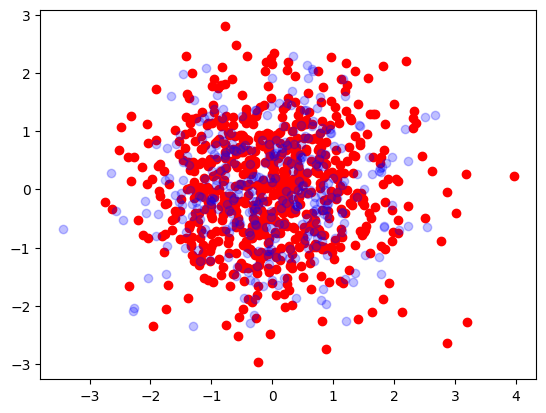

tensor(1)
tensor(0)


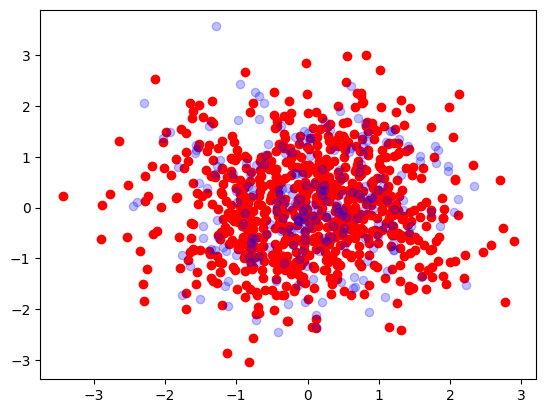

tensor(1)
tensor(2)


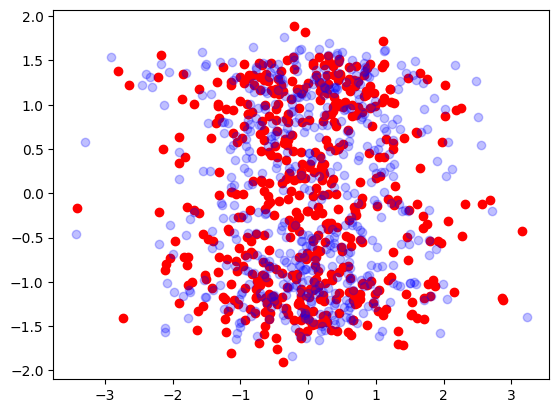

tensor(2)
tensor(1)


<Figure size 640x480 with 0 Axes>

In [14]:
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from CITNP.utils.datautils import transformer_inference_split_withpadding


data_loader = DataLoader(
    generator, batch_size=None,
    collate_fn=transformer_inference_split_withpadding(
        cntxt_split=[0.2, 0.8],
        sample_size=1000
    )
)


for idx, batch in enumerate(data_loader):
    (
        context, target, intvn_indices, outcome_indices, masks
    ) = batch

    plt.scatter(context[0][:,0], context[0][:,1], c='r')
    plt.scatter(target[0][:,0], target[0][:,1], c='b', alpha=0.25)
    plt.show()
    plt.clf()
    print(intvn_indices[0])
    print(outcome_indices[0])

In [10]:
context.shape

torch.Size([1, 1437, 3, 1])